In [1]:
import os
import zipfile
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import pickle

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42

In [2]:
df = pd.read_excel('data/default of credit card clients.xls',
                  header=1)

df.head().T

/var/folders/lz/rnk_4r4n3hd4rbc6fcfp0pdh0000gn/T/ipykernel_19568/155842500.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel('data/default of credit card clients.xls',


,0,1,2,3,4
ID,1,2,3,4,5
LIMIT_BAL,20000,120000,90000,50000,50000
SEX,2,2,2,2,1
EDUCATION,2,2,2,2,2
MARRIAGE,1,2,2,1,1
AGE,24,26,34,37,57
PAY_0,2,-1,0,0,-1
PAY_2,2,2,0,0,0
PAY_3,-1,0,0,0,-1
PAY_4,-1,0,0,0,0


In [3]:
df.shape

(30000, 25)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [5]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000,30000.000
mean,15000.500,167484.323,1.604,1.853,1.552,35.486,-0.017,-0.134,-0.166,-0.221,-0.266,-0.291,51223.331,49179.075,47013.155,43262.949,40311.401,38871.760,5663.581,5921.163,5225.681,4826.077,4799.388,5215.503,0.221
std,8660.398,129747.662,0.489,0.790,0.522,9.218,1.124,1.197,1.197,1.169,1.133,1.150,73635.861,71173.769,69349.387,64332.856,60797.156,59554.108,16563.280,23040.870,17606.961,15666.160,15278.306,17777.466,0.415
min,1.000,10000.000,1.000,0.000,0.000,21.000,-2.000,-2.000,-2.000,-2.000,-2.000,-2.000,-165580.000,-69777.000,-157264.000,-170000.000,-81334.000,-339603.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,7500.750,50000.000,1.000,1.000,1.000,28.000,-1.000,-1.000,-1.000,-1.000,-1.000,-1.000,3558.750,2984.750,2666.250,2326.750,1763.000,1256.000,1000.000,833.000,390.000,296.000,252.500,117.750,0.000
50%,15000.500,140000.000,2.000,2.000,2.000,34.000,0.000,0.000,0.000,0.000,0.000,0.000,22381.500,21200.000,20088.500,19052.000,18104.500,17071.000,2100.000,2009.000,1800.000,1500.000,1500.000,1500.000,0.000
75%,22500.250,240000.000,2.000,2.000,2.000,41.000,0.000,0.000,0.000,0.000,0.000,0.000,67091.000,64006.250,60164.750,54506.000,50190.500,49198.250,5006.000,5000.000,4505.000,4013.250,4031.500,4000.000,0.000
max,30000.000,1000000.000,2.000,6.000,3.000,79.000,8.000,8.000,8.000,8.000,8.000,8.000,964511.000,983931.000,1664089.000,891586.000,927171.000,961664.000,873552.000,1684259.000,896040.000,621000.000,426529.000,528666.000,1.000


In [6]:
# standardize column names
df.columns = (
    df.columns.str.lower().str.replace(' ', '_')
)
df.columns

Index(['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0',
       'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2',
       'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6',
       'default_payment_next_month'],
      dtype='str')

In [7]:
df = df.rename(
    columns={'default_payment_next_month': 'default'}
)

df.columns.to_list()

['id',
 'limit_bal',
 'sex',
 'education',
 'marriage',
 'age',
 'pay_0',
 'pay_2',
 'pay_3',
 'pay_4',
 'pay_5',
 'pay_6',
 'bill_amt1',
 'bill_amt2',
 'bill_amt3',
 'bill_amt4',
 'bill_amt5',
 'bill_amt6',
 'pay_amt1',
 'pay_amt2',
 'pay_amt3',
 'pay_amt4',
 'pay_amt5',
 'pay_amt6',
 'default']

In [8]:
# Checking for missing values
df.isnull().sum()

id           0
limit_bal    0
sex          0
education    0
marriage     0
age          0
pay_0        0
pay_2        0
pay_3        0
pay_4        0
pay_5        0
pay_6        0
bill_amt1    0
bill_amt2    0
bill_amt3    0
bill_amt4    0
bill_amt5    0
bill_amt6    0
pay_amt1     0
pay_amt2     0
pay_amt3     0
pay_amt4     0
pay_amt5     0
pay_amt6     0
default      0
dtype: int64

In [9]:
#duplicated records
df.duplicated().sum()

np.int64(0)

In [10]:
#check for unique column IDs
df.id.unique()

array([    1,     2,     3, ..., 29998, 29999, 30000], shape=(30000,))

In [11]:
#Examine the target variables
df.default.value_counts(normalize=True)

default
0   0.779
1   0.221
Name: proportion, dtype: float64

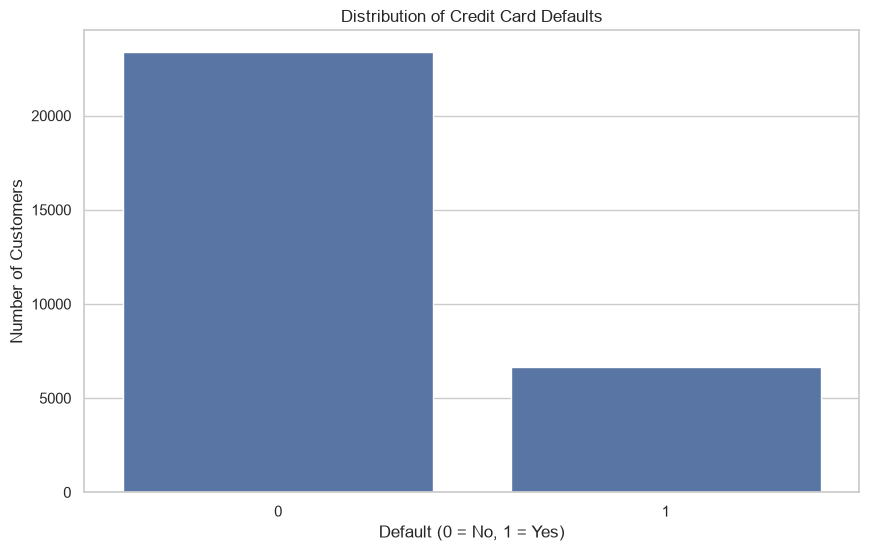

In [12]:
sns.countplot(data=df, x='default')
plt.title('Distribution of Credit Card Defaults')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()

Approximately 22% of customers defaulted on their payments. Since the majority did not default, accuracy alone would be misleading. We'll prioritize ROC AUC for model selection and also examine precision, recall, and F1-score.

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,30000.000,15000.500,8660.398,1.000,7500.750,15000.500,22500.250,30000.000
limit_bal,30000.000,167484.323,129747.662,10000.000,50000.000,140000.000,240000.000,1000000.000
sex,30000.000,1.604,0.489,1.000,1.000,2.000,2.000,2.000
education,30000.000,1.853,0.790,0.000,1.000,2.000,2.000,6.000
marriage,30000.000,1.552,0.522,0.000,1.000,2.000,2.000,3.000
age,30000.000,35.486,9.218,21.000,28.000,34.000,41.000,79.000
pay_0,30000.000,-0.017,1.124,-2.000,-1.000,0.000,0.000,8.000
pay_2,30000.000,-0.134,1.197,-2.000,-1.000,0.000,0.000,8.000
pay_3,30000.000,-0.166,1.197,-2.000,-1.000,0.000,0.000,8.000
pay_4,30000.000,-0.221,1.169,-2.000,-1.000,0.000,0.000,8.000


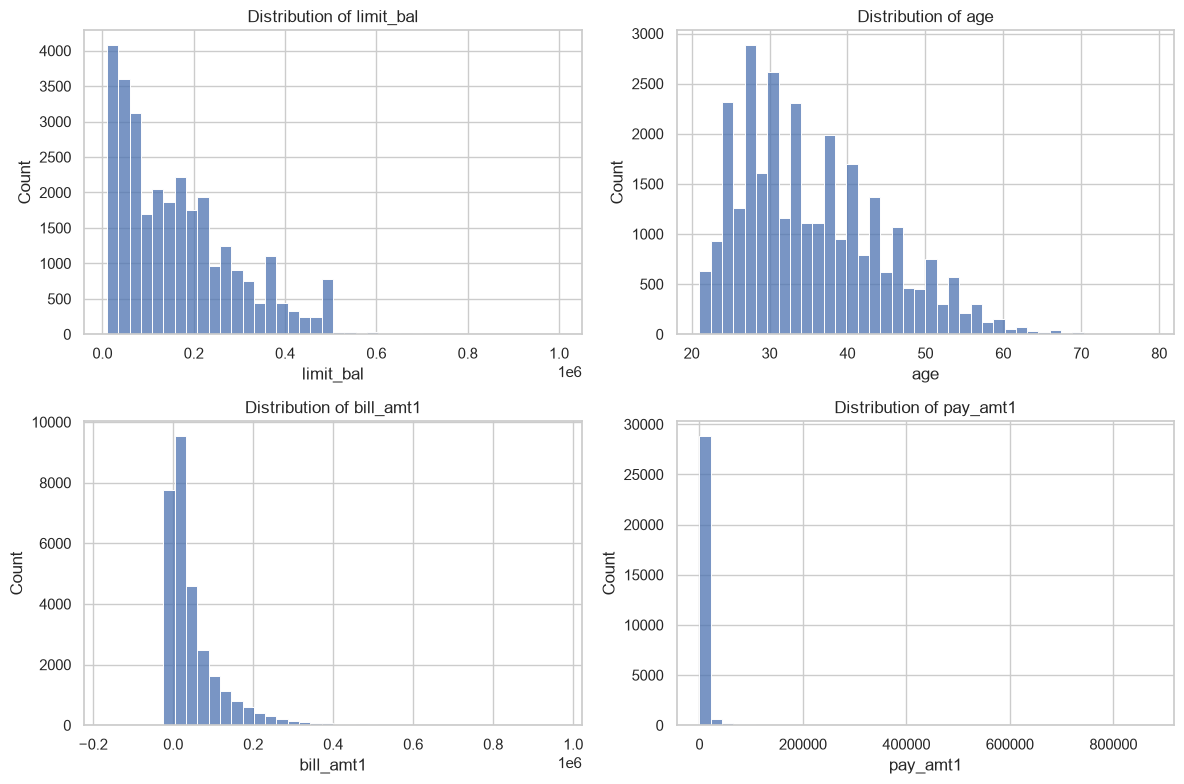

In [14]:
numerical_features = [
    'limit_bal',
    'age',
    'bill_amt1',
    'pay_amt1'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(numerical_features, axes.flatten()):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [15]:
df.groupby('default')['limit_bal'].agg(
    ['mean', 'median', 'min', 'max']
)

,mean,median,min,max
default,,,,
0,178099.726,150000.000,10000,1000000
1,130109.656,90000.000,10000,740000


In [16]:
df.groupby('pay_0')['default'].agg(
    ['count', 'mean']
)

,count,mean
pay_0,,
-2,2759,0.132
-1,5686,0.168
0,14737,0.128
1,3688,0.339
2,2667,0.691
3,322,0.758
4,76,0.684
5,26,0.500
6,11,0.545


In [17]:
# Select numerical features
numerical = [
    col for col in df.columns
    if col not in ['id', 'default', 'sex', 'education', 'marriage']
]

# Calculate correlations with target
correlations = (
    df[numerical + ['default']]
    .corr()['default']
    .drop('default')
    .sort_values(ascending=False)
)

correlations

pay_0        0.325
pay_2        0.264
pay_3        0.235
pay_4        0.217
pay_5        0.204
pay_6        0.187
age          0.014
bill_amt6   -0.005
bill_amt5   -0.007
bill_amt4   -0.010
bill_amt3   -0.014
bill_amt2   -0.014
bill_amt1   -0.020
pay_amt6    -0.053
pay_amt5    -0.055
pay_amt3    -0.056
pay_amt4    -0.057
pay_amt2    -0.059
pay_amt1    -0.073
limit_bal   -0.154
Name: default, dtype: float64

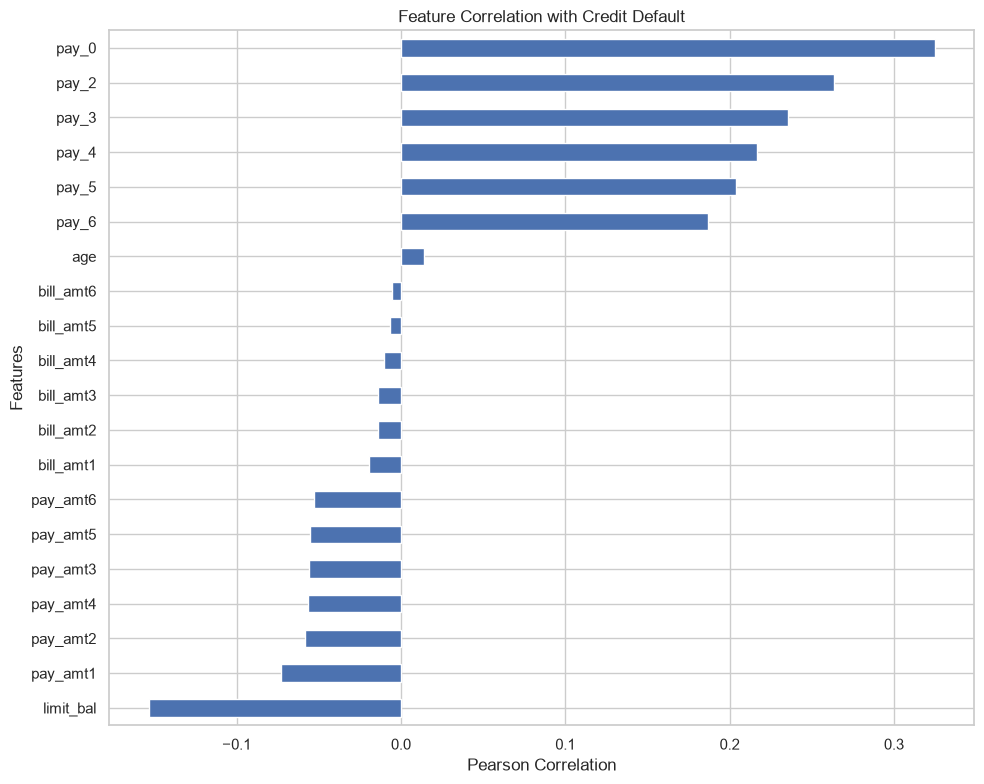

In [18]:
plt.figure(figsize=(10, 8))

correlations.sort_values().plot(kind='barh')

plt.title('Feature Correlation with Credit Default')
plt.xlabel('Pearson Correlation')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [19]:
#split dataset into train, test, and validation
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df['default']
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df_full_train['default']
)

print("Training:", len(df_train))
print("Validation:", len(df_val))
print("Testing:", len(df_test))

Training: 18000
Validation: 6000
Testing: 6000


In [20]:
y_train = df_train['default'].values
y_val = df_val['default'].values
y_test = df_test['default'].values

# Remove target and customer ID from model features
df_train = df_train.drop(columns=['default', 'id']).copy()
df_val = df_val.drop(columns=['default', 'id']).copy()
df_test = df_test.drop(columns=['default', 'id']).copy()

In [21]:
#verify class imbalance

print("Training default rate:", y_train.mean())
print("Validation default rate:", y_val.mean())
print("Testing default rate:", y_test.mean())

Training default rate: 0.2212222222222222
Validation default rate: 0.22116666666666668
Testing default rate: 0.22116666666666668


In [22]:
#prepare categorical and numerical features

categorical = ['sex', 'education', 'marriage']

numerical = [
    col for col in df_train.columns
    if col not in categorical
]

#Convert categorical to strings
for dataset in [df_train, df_val, df_test]:
    dataset[categorical] = dataset[categorical].astype(str)

print("Categorical:", categorical)
print("Numerical:", numerical)

Categorical: ['sex', 'education', 'marriage']
Numerical: ['limit_bal', 'age', 'pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2', 'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1', 'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6']


In [23]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (18000, 33)
X_val: (6000, 33)


In [24]:
#Scale the numerical features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

In [25]:
# Train Logistic Regression model
model = LogisticRegression(
    solver='liblinear',
    max_iter=1000,
    random_state=RANDOM_STATE
)

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

## Evaluate the base model

In [26]:
y_pred = model.predict_proba(X_val_scaled)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(f"Validation ROC AUC: {auc:.3f}")

Validation ROC AUC: 0.726


## Train the baseline Decision Tree

In [27]:
dt = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(f"Decision Tree ROC AUC: {auc:.3f}")

Decision Tree ROC AUC: 0.610


In [28]:
scores = []

for depth in [3, 4, 5, 6, 10, 15, 20]:
    for leaf in [1, 5, 10, 15, 20, 50, 100]:

        dt = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=RANDOM_STATE
        )

        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((depth, leaf, auc))

df_scores = pd.DataFrame(
    scores,
    columns=['max_depth', 'min_samples_leaf', 'auc']
)

df_scores.sort_values(
    by='auc',
    ascending=False
).head(10)

,max_depth,min_samples_leaf,auc
34,10,100,0.769
33,10,50,0.768
48,20,100,0.766
41,15,100,0.765
26,6,50,0.765
40,15,50,0.765
27,6,100,0.763
47,20,50,0.763
25,6,20,0.761
24,6,15,0.760


Awesome! Our Tuned decision tree model on `max_depth` 10 and `min_samples_leaf` 100 has outperformed the Logistic Regression model.

### Train the baseline Random Forest Classifier model

In [29]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(f"Random Forest ROC AUC: {auc:.3f}")

Random Forest ROC AUC: 0.773


In [30]:
#Tune Random forest
scores = []

for n in [50, 100, 150]:
    for depth in [5, 10, 15]:
        for leaf in [1, 5, 10, 20]:

            rf = RandomForestClassifier(
                n_estimators=n,
                max_depth=depth,
                min_samples_leaf=leaf,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

            rf.fit(X_train, y_train)

            y_pred = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)

            scores.append((n, depth, leaf, auc))

df_rf_scores = pd.DataFrame(
    scores,
    columns=[
        'n_estimators',
        'max_depth',
        'min_samples_leaf',
        'auc'
    ]
)

df_rf_scores.sort_values(
    by='auc',
    ascending=False
).head(10)

,n_estimators,max_depth,min_samples_leaf,auc
34,150,15,10,0.788
10,50,15,10,0.788
22,100,15,10,0.788
35,150,15,20,0.786
23,100,15,20,0.786
11,50,15,20,0.786
32,150,15,1,0.785
33,150,15,5,0.784
31,150,10,20,0.784
30,150,10,10,0.784


**The results suggest that several Random Forest configurations perform similarly. The top three use `max_depth`=15 and `min_samples_leaf`=10, with 50, 100, or 150 trees. Using 100 trees is a reasonable compromise between computational cost and predictive performance.**

In [31]:
best_params = {
    'n_estimators': 100,
    'max_depth': 15,
    'min_samples_leaf': 10,
    'random_state': 42,
    'n_jobs': -1
}

In [32]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train_fold = df_full_train.iloc[train_idx].copy()
    df_val_fold = df_full_train.iloc[val_idx].copy()

    y_train_fold = df_train_fold['default'].values
    y_val_fold = df_val_fold['default'].values

    df_train_fold = df_train_fold.drop(columns=['default', 'id'])
    df_val_fold = df_val_fold.drop(columns=['default', 'id'])

    categorical = ['sex', 'education', 'marriage']

    df_train_fold[categorical] = df_train_fold[categorical].astype(str)
    df_val_fold[categorical] = df_val_fold[categorical].astype(str)

    train_dicts = df_train_fold.to_dict(orient='records')
    val_dicts = df_val_fold.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)

    X_train_fold = dv.fit_transform(train_dicts)
    X_val_fold = dv.transform(val_dicts)

    model = RandomForestClassifier(**best_params)

    model.fit(X_train_fold, y_train_fold)

    y_pred = model.predict_proba(X_val_fold)[:, 1]

    auc = roc_auc_score(y_val_fold, y_pred)

    scores.append(auc)

print("Fold AUC scores:", np.round(scores, 3))
print(f"Mean ROC AUC: {np.mean(scores):.3f}")
print(f"Standard deviation: {np.std(scores):.3f}")

Fold AUC scores: [0.778 0.781 0.788 0.782 0.789]
Mean ROC AUC: 0.784
Standard deviation: 0.004


The result above indicates that our Random Forest model is performing consistently across all five folds and the low standard deviation suggest a stable performance across these folds.

## Train the final model

In [33]:
# Prepare full training data
df_full_train_final = df_full_train.copy()

y_full_train = df_full_train_final['default'].values

df_full_train_final = df_full_train_final.drop(
    columns=['default', 'id']
)

categorical = ['sex', 'education', 'marriage']

df_full_train_final[categorical] = (
    df_full_train_final[categorical].astype(str)
)

# Prepare test features
df_test_final = df_test.copy()

df_test_final[categorical] = (
    df_test_final[categorical].astype(str)
)

# DictVectorizer
dv = DictVectorizer(sparse=False)

train_dicts = df_full_train_final.to_dict(orient='records')
test_dicts = df_test_final.to_dict(orient='records')

X_full_train = dv.fit_transform(train_dicts)
X_test = dv.transform(test_dicts)

# Train final Random Forest
final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_full_train, y_full_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

## Evaluate on the test data

In [34]:
# Predict probabilities
y_test_pred = final_model.predict_proba(X_test)[:, 1]

# Evaluate ROC AUC
test_auc = roc_auc_score(y_test, y_test_pred)

print(f"Final Test ROC AUC: {test_auc:.3f}")

Final Test ROC AUC: 0.774


In [35]:
#evaluate classification performance at the default threshold of 0.5
y_test_binary = (y_test_pred >= 0.5).astype(int)

print(classification_report(y_test, y_test_binary))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_binary))

              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.36      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.68      6000
weighted avg       0.80      0.82      0.80      6000

Confusion Matrix:
[[4431  242]
 [ 847  480]]


,feature,importance
19,pay_0,0.246
20,pay_2,0.099
21,pay_3,0.063
14,limit_bal,0.044
25,pay_amt1,0.042
1,bill_amt1,0.040
26,pay_amt2,0.036
2,bill_amt2,0.035
27,pay_amt3,0.034
22,pay_4,0.033


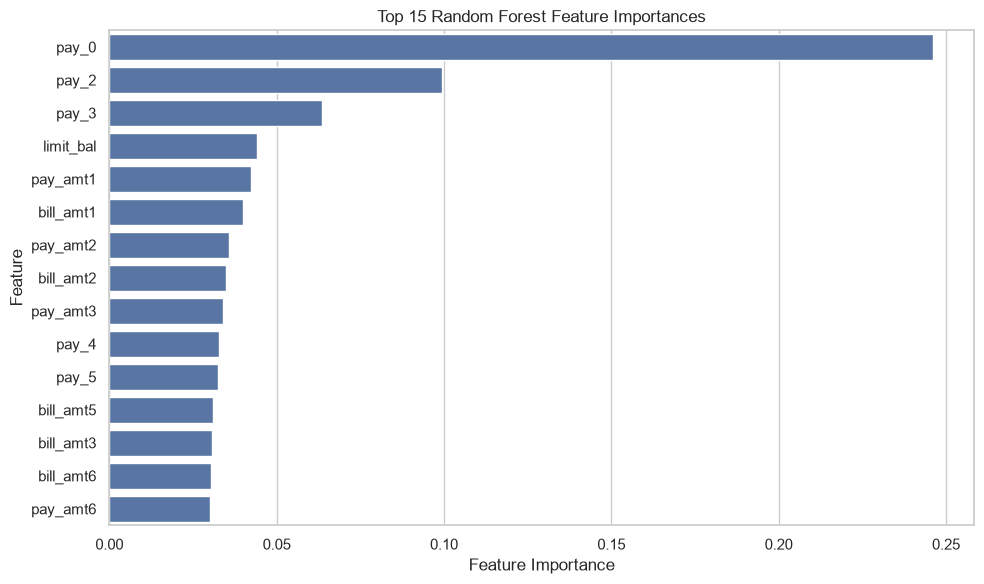

In [38]:
# Random Forest feature importance
feature_names = dv.get_feature_names_out()

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='importance',
    ascending=False
)

display(feature_importance.head(15))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='importance',
    y='feature'
)

plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Save the model using `pickle`

In [36]:
output_file = 'models/credit_risk_model.bin'

with open(output_file, 'wb') as f_out:
    pickle.dump((dv, final_model), f_out)

print(f'Model saved to {output_file}')

Model saved to models/credit_risk_model.bin


## Verify the save

In [37]:
with open(output_file, 'rb') as f_in:
    dv_loaded, model_loaded = pickle.load(f_in)

# Verify predictions
X_test_loaded = dv_loaded.transform(test_dicts)

y_pred_loaded = model_loaded.predict_proba(X_test_loaded)[:, 1]

print('Loaded model ROC AUC:', roc_auc_score(y_test, y_pred_loaded))

Loaded model ROC AUC: 0.7740259706750656
